# Week 10 – LLM-Guided Backtest

Runs the LLM-guided historical simulation (Week 8) for every ticker in `TICKERS`, collects the realised P&L of closed trades, and computes Sharpe, max drawdown and win rate with `src/evaluation/metrics.py`.

Note: the equity curve here is built from realised P&L per closed trade, so Sharpe is per trade, not daily. Each ticker runs the full LLM simulation, which can be slow.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.evaluation.metrics import compute_sharpe, compute_max_drawdown, compute_win_rate
from src.simulation.orchestrator import simulate_historical

In [1]:
TICKERS = ["AAPL", "MSFT", "GOOGL"]      # edit this list
start_date = "2026-06-01"
end_date   = "2026-10-05"
starting_capital = 10_000.0

sims = {}
for t in TICKERS:
    print(f"Running simulation for {t} from {start_date} to {end_date}...")
    try:
        sims[t] = simulate_historical(
            ticker=t, start_date=start_date, end_date=end_date,
            portfolio_value=starting_capital,
            verbose=False,  # set True to see per-day output
        )
    except Exception as exc:
        print(f"{t}: skipped ({type(exc).__name__}: {exc})")

Running simulation for AAPL from 2026-06-01 to 2026-10-05...
AAPL: skipped (NameError: name 'simulate_historical' is not defined)
Running simulation for MSFT from 2026-06-01 to 2026-10-05...
MSFT: skipped (NameError: name 'simulate_historical' is not defined)
Running simulation for GOOGL from 2026-06-01 to 2026-10-05...
GOOGL: skipped (NameError: name 'simulate_historical' is not defined)


In [ ]:
equities = {}
rows = []
for t, sim in sims.items():
    trades = sim.get("closed_trades", [])
    pnls = [tr.get("pnl", 0.0) for tr in trades]
    equity = np.array([starting_capital] + list(np.cumsum(pnls) + starting_capital))
    equities[t] = equity
    if pnls:
        returns = np.diff(equity) / equity[:-1]
        rows.append({
            "Ticker": t, "Closed trades": len(pnls),
            "Sharpe (per trade)": f"{compute_sharpe(returns):.3f}",
            "Max Drawdown": f"{compute_max_drawdown(equity):.2%}",
            "Win Rate": f"{sum(p > 0 for p in pnls) / len(pnls):.2%}",
            "Total Return": f"{equity[-1] / starting_capital - 1:.2%}",
            "Final Equity": f"${equity[-1]:,.2f}",
        })
    else:
        rows.append({"Ticker": t, "Closed trades": 0})
display(pd.DataFrame(rows, columns=[
    "Ticker", "Closed trades", "Sharpe (per trade)", "Max Drawdown",
    "Win Rate", "Total Return", "Final Equity",
]).set_index("Ticker"))

,Closed trades,Sharpe (per trade),Max Drawdown,Win Rate,Total Return,Final Equity
Ticker,,,,,,


C:\Users\Zamuxolo\AppData\Local\Temp\ipykernel_37672\367473817.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(); plt.grid(True)


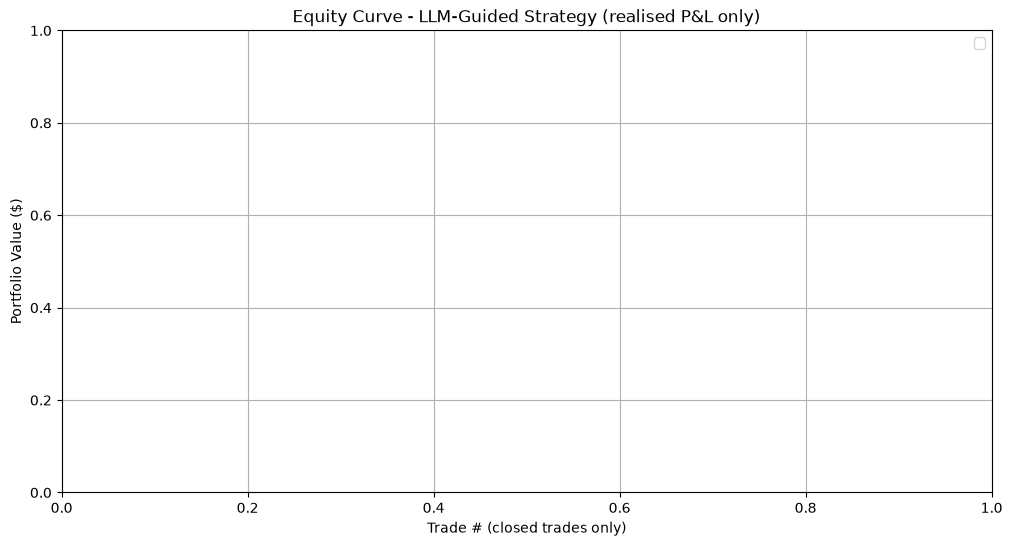

In [5]:
plt.figure(figsize=(12, 6))
for t, eq in equities.items():
    plt.plot(np.arange(len(eq)), eq, marker="o", label=t)
plt.title("Equity Curve - LLM-Guided Strategy (realised P&L only)")
plt.ylabel("Portfolio Value ($)")
plt.xlabel("Trade # (closed trades only)")
plt.legend(); plt.grid(True)
plt.show()

In [ ]:
# OPTIONAL: daily signals from each simulation.
# result["daily_results"] is a list of {"date", "result"}; adjust the keys below
# if your run_daily_cycle returns different names.
frames = []
for t, sim in sims.items():
    rows = []
    for dr in sim.get("daily_results", []):
        res = dr.get("result") if isinstance(dr, dict) else None
        if isinstance(res, dict):
            signal = res.get("signal", {})
            if signal:
                rows.append({"ticker": t, "date": dr.get("date"),
                             "action": signal.get("action"),
                             "confidence": signal.get("confidence")})
    if rows:
        frames.append(pd.DataFrame(rows))

if frames:
    signals_df = pd.concat(frames, ignore_index=True)
    print(f"Extracted {len(signals_df)} daily signals.")
    display(signals_df.groupby("ticker").head(5))
else:
    print("No signal information found in daily_results.")